# Visualization

This notebook uses the saved benchmark comparison data to find a 35-part strip-order dataset where two Rectpack configurations had the largest difference in sheet count. It then reruns those configurations and PackingSolver on the same parts and sheet dimensions, with rotation disabled, and plots their layouts side by side. The visual comparison shows how each solver arranged the parts and how many sheets it used; the saved benchmark data remains the source for the aggregate results.

It uses CSV files generated by `scripts/compare_solver_benchmarks.py`.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent 
COMPARISON_DIR = PROJECT_ROOT / "results"/"comparison"

In [2]:
import pandas as pd

best_summary = pd.read_csv(COMPARISON_DIR/'comparison_to_best_observed_summary.csv')
best_paired = pd.read_csv(COMPARISON_DIR/'comparison_to_best_observed_paired.csv')

best_summary.head()

,rotation,datasets,baseline_total_sheets,candidate_total_sheets,sheets_saved,candidate_wins,ties,candidate_losses,relative_reduction,source,solver,config_id
0,True,29,377,377,0,0,29,0,0.000000,results/packingsolver/pilot_v1_results.csv,packingsolver,BinPacking__time30s
1,False,30,402,402,0,0,30,0,0.000000,results/packingsolver/pilot_v1_results.csv,packingsolver,BinPacking__time30s
2,True,29,377,388,-11,0,19,10,-0.029178,results/rectpack/pilot_v1_results.csv,rectpack,MaxRectsBaf__long_side__BBF
3,False,30,402,417,-15,0,18,12,-0.037313,results/rectpack/pilot_v1_results.csv,rectpack,MaxRectsBssf__area__BBF
4,True,29,377,406,-29,0,7,22,-0.076923,results/rectpack/pilot_v1_results.csv,rectpack,SkylineBl__long_side__BBF


Order the solvers:

In [3]:
best_summary.sort_values(by=['rotation','relative_reduction'],ascending=False)[['rotation', 'sheets_saved', 'relative_reduction','solver','config_id']]

,rotation,sheets_saved,relative_reduction,solver,config_id
0,True,0,0.000000,packingsolver,BinPacking__time30s
23,True,-10,-0.026525,rectpack,MaxRectsBssf__long_side__BBF
2,True,-11,-0.029178,rectpack,MaxRectsBaf__long_side__BBF
9,True,-14,-0.037135,rectpack,GuillotineBafSas__long_side__BBF
26,True,-14,-0.037135,rectpack,MaxRectsBssf__area__BBF
25,True,-15,-0.039788,rectpack,MaxRectsBaf__area__BBF
12,True,-18,-0.047745,rectpack,MaxRectsBaf__short_side__BBF
22,True,-22,-0.058355,rectpack,MaxRectsBssf__short_side__BBF
27,True,-24,-0.063660,rectpack,SkylineBl__short_side__BBF
24,True,-25,-0.066313,rectpack,SkylineBl__area__BBF


The best RectPack configuration was MaxRectsBssf__long_side__BBF, the worse RectPack configuration was GuillotineBafSas__short_side__BBF

Find a dataset with a biggest difference in sheet count for Packing Solver and best and worst RectPack

In [4]:
best_rp = 'MaxRectsBssf__long_side__BBF'
worst_rp = 'GuillotineBafSas__short_side__BBF'

best_paired[best_paired['config_id']==best_rp].sort_values(by='relative_reduction').head()



,dataset_id,rotation,sheets_used_baseline,sheets_used_candidate,sheets_saved,relative_reduction,candidate_outcome,source,solver,config_id
232,rect_v1_strips_sheet2500x1250_n35_seed1,False,3,4,-1,-0.333333,loss,results/rectpack/pilot_v1_results.csv,rectpack,MaxRectsBssf__long_side__BBF
234,rect_v1_strips_sheet2500x1250_n35_seed3,False,3,4,-1,-0.333333,loss,results/rectpack/pilot_v1_results.csv,rectpack,MaxRectsBssf__long_side__BBF
705,rect_v1_strips_sheet2500x1250_n35_seed1,True,3,4,-1,-0.333333,loss,results/rectpack/pilot_v1_results.csv,rectpack,MaxRectsBssf__long_side__BBF
230,rect_v1_strips_sheet2500x1250_n100_seed4,False,7,9,-2,-0.285714,loss,results/rectpack/pilot_v1_results.csv,rectpack,MaxRectsBssf__long_side__BBF
229,rect_v1_strips_sheet2500x1250_n100_seed3,False,7,9,-2,-0.285714,loss,results/rectpack/pilot_v1_results.csv,rectpack,MaxRectsBssf__long_side__BBF


In [5]:
best_paired[best_paired['config_id']==worst_rp].sort_values(by='relative_reduction').head()

,dataset_id,rotation,sheets_used_baseline,sheets_used_candidate,sheets_saved,relative_reduction,candidate_outcome,source,solver,config_id
532,rect_v1_strips_sheet2500x1250_n35_seed4,False,3,10,-7,-2.333333,loss,results/rectpack/pilot_v1_results.csv,rectpack,GuillotineBafSas__short_side__BBF
531,rect_v1_strips_sheet2500x1250_n35_seed3,False,3,10,-7,-2.333333,loss,results/rectpack/pilot_v1_results.csv,rectpack,GuillotineBafSas__short_side__BBF
942,rect_v1_strips_sheet2500x1250_n35_seed3,True,3,10,-7,-2.333333,loss,results/rectpack/pilot_v1_results.csv,rectpack,GuillotineBafSas__short_side__BBF
529,rect_v1_strips_sheet2500x1250_n35_seed1,False,3,9,-6,-2.000000,loss,results/rectpack/pilot_v1_results.csv,rectpack,GuillotineBafSas__short_side__BBF
940,rect_v1_strips_sheet2500x1250_n35_seed1,True,3,9,-6,-2.000000,loss,results/rectpack/pilot_v1_results.csv,rectpack,GuillotineBafSas__short_side__BBF


Choosing a dataset were the relative reduction was the biggest and reruning and visualising the result:

In [6]:
from cutting_benchmark.rectangle_datasets import load_datasets

DATASET_ID = 'rect_v1_strips_sheet2500x1250_n35_seed3'

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "synthetic"
    / "pilot_v1.json"
)

datasets = load_datasets(DATASET_PATH)

dataset = next(
    d for d in datasets
    if d["dataset_id"] == DATASET_ID
)

Rectpack: 

In [7]:
from cutting_benchmark.solvers.rectpack_adapter import (
    ALGORITHMS,
    SORTS,
    run_pack,
)

best_algorithm, best_sort, *_ = best_rp.split("__")

best_rp_results = run_pack(
    parts=dataset["parts"],
    algorithm=best_algorithm,
    sort=best_sort,
    rotation=False,
    sheet_size=(2500, 1250),
    available_sheets=None,
    return_layout=True,
)

best_rp_metrics = {
    key: value
    for key, value in best_rp_results.items()
    if key not in {"placements", "used_sheets"}
}

display(pd.DataFrame([best_rp_metrics]))

,solver,config_id,algorithm,sort,rotation,bin_selection,sheet_width,sheet_height,available_sheets,runtime_seconds,...,complete,individually_feasible,sheets_used,requested_area,packed_area,part_fraction,area_fraction,utilisation,area_lower_bound,sheet_gap_to_area_bound
0,rectpack,MaxRectsBssf__long_side__BBF,MaxRectsBssf,long_side,False,BBF,2500,1250,35,0.001286,...,True,True,4,7498980,7498980,1.0,1.0,0.599918,3,1


In [8]:
worst_algorithm, worst_sort, *_ = worst_rp.split("__")

worst_rp_results = run_pack(
    parts=dataset["parts"],
    algorithm=worst_algorithm,
    sort=worst_sort,
    rotation=False,
    sheet_size=(2500, 1250),
    available_sheets=None,
    return_layout=True,
)

worst_rp_metrics = {
    key: value
    for key, value in worst_rp_results.items()
    if key not in {"placements", "used_sheets"}
}

display(pd.DataFrame([worst_rp_metrics]))

,solver,config_id,algorithm,sort,rotation,bin_selection,sheet_width,sheet_height,available_sheets,runtime_seconds,...,complete,individually_feasible,sheets_used,requested_area,packed_area,part_fraction,area_fraction,utilisation,area_lower_bound,sheet_gap_to_area_bound
0,rectpack,GuillotineBafSas__short_side__BBF,GuillotineBafSas,short_side,False,BBF,2500,1250,35,0.000805,...,True,True,10,7498980,7498980,1.0,1.0,0.239967,3,7


(<Figure size 2000x500 with 4 Axes>,
 array([<Axes: title={'center': 'Sheet 1 — 90.3% utilisation\n16 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 2 — 77.7% utilisation\n10 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 3 — 67.0% utilisation\n8 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 4 — 4.9% utilisation\n1 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>],
       dtype=object))

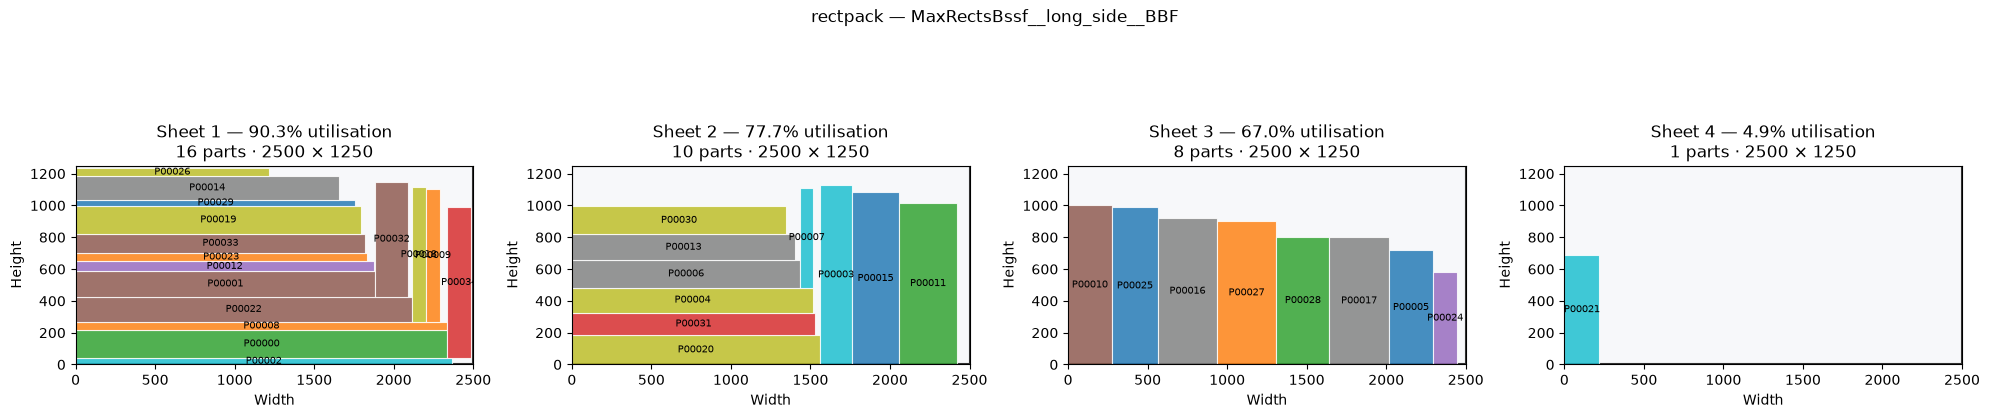

In [9]:
from cutting_benchmark.rectangle_visualization import plot_rectangle_result

plot_rectangle_result(best_rp_results)

(<Figure size 5000x500 with 10 Axes>,
 array([<Axes: title={'center': 'Sheet 1 — 65.9% utilisation\n8 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 2 — 40.3% utilisation\n5 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 3 — 26.8% utilisation\n4 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 4 — 37.2% utilisation\n5 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 5 — 29.8% utilisation\n4 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 6 — 17.2% utilisation\n3 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 7 — 9.1% utilisation\n2 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 8 — 6.9% utilisation\n2 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height

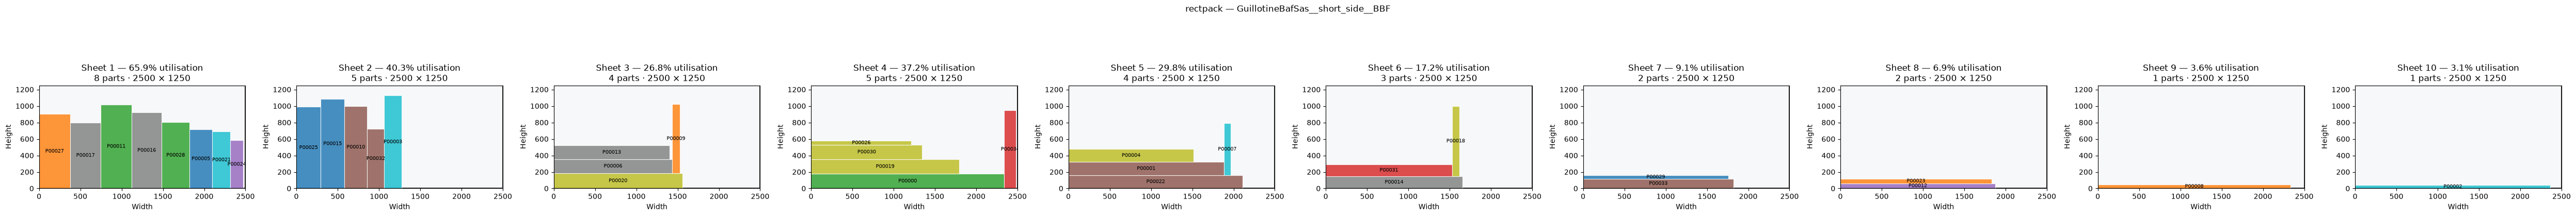

In [10]:
plot_rectangle_result(worst_rp_results)

Explore packing solver:

In [11]:
from cutting_benchmark.solvers.packingsolver_adapter import run_pack as run_packingsolver

ps_results = run_packingsolver(
    parts=dataset["parts"],
    rotation=False,
    time_limit=30,
    sheet_size=(2500, 1250),
    available_sheets=None,
    return_layout=True,
)

ps_metrics = {
    key: value
    for key, value in ps_results.items()
    if key not in {"placements", "used_sheets"}
}

display(pd.DataFrame([ps_metrics]))

,solver,config_id,objective,rotation,time_limit_seconds,sheet_width,sheet_height,available_sheets,runtime_seconds,layout_valid,...,complete,individually_feasible,sheets_used,requested_area,packed_area,part_fraction,area_fraction,utilisation,area_lower_bound,sheet_gap_to_area_bound
0,packingsolver,BinPacking__time30s,BinPacking,False,30,2500,1250,35,0.355128,True,...,True,True,3,7498980,7498980,1.0,1.0,0.799891,3,0


(<Figure size 1500x500 with 3 Axes>,
 array([<Axes: title={'center': 'Sheet 1 — 88.3% utilisation\n14 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 2 — 84.6% utilisation\n9 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
        <Axes: title={'center': 'Sheet 3 — 67.1% utilisation\n12 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>],
       dtype=object))

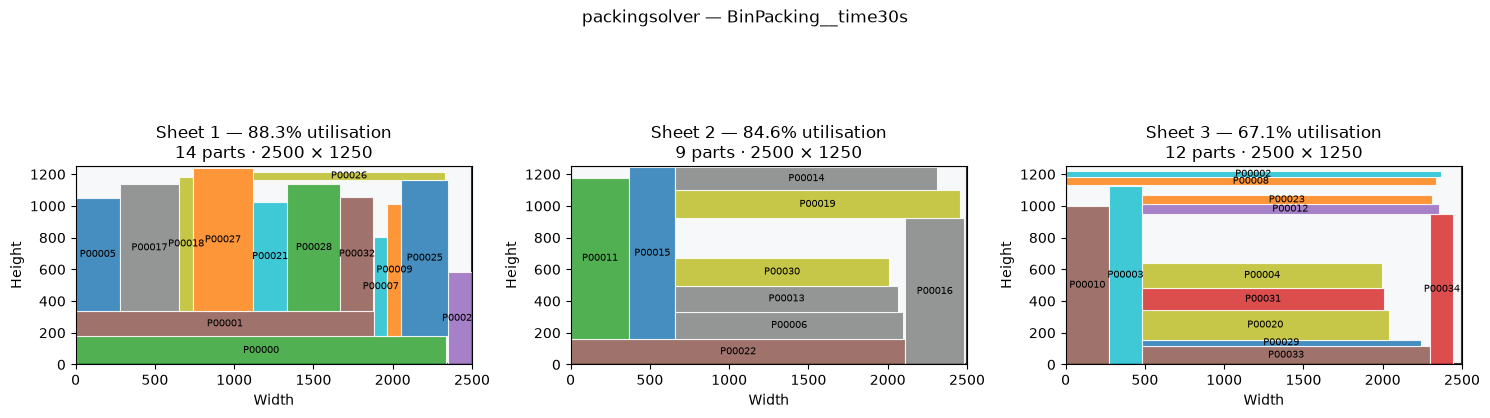

In [12]:
plot_rectangle_result(ps_results)

Compare results:

(<Figure size 5000x1350 with 30 Axes>,
 array([[<Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 1 — 88.3% utilisation\n14 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 2 — 84.6% utilisation\n9 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 3 — 67.1% utilisation\n12 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 4 — not used'}>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 5 — not used'}>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 6 — not used'}>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 7 — not used'}>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 8 — not used'}>,
         <Ax

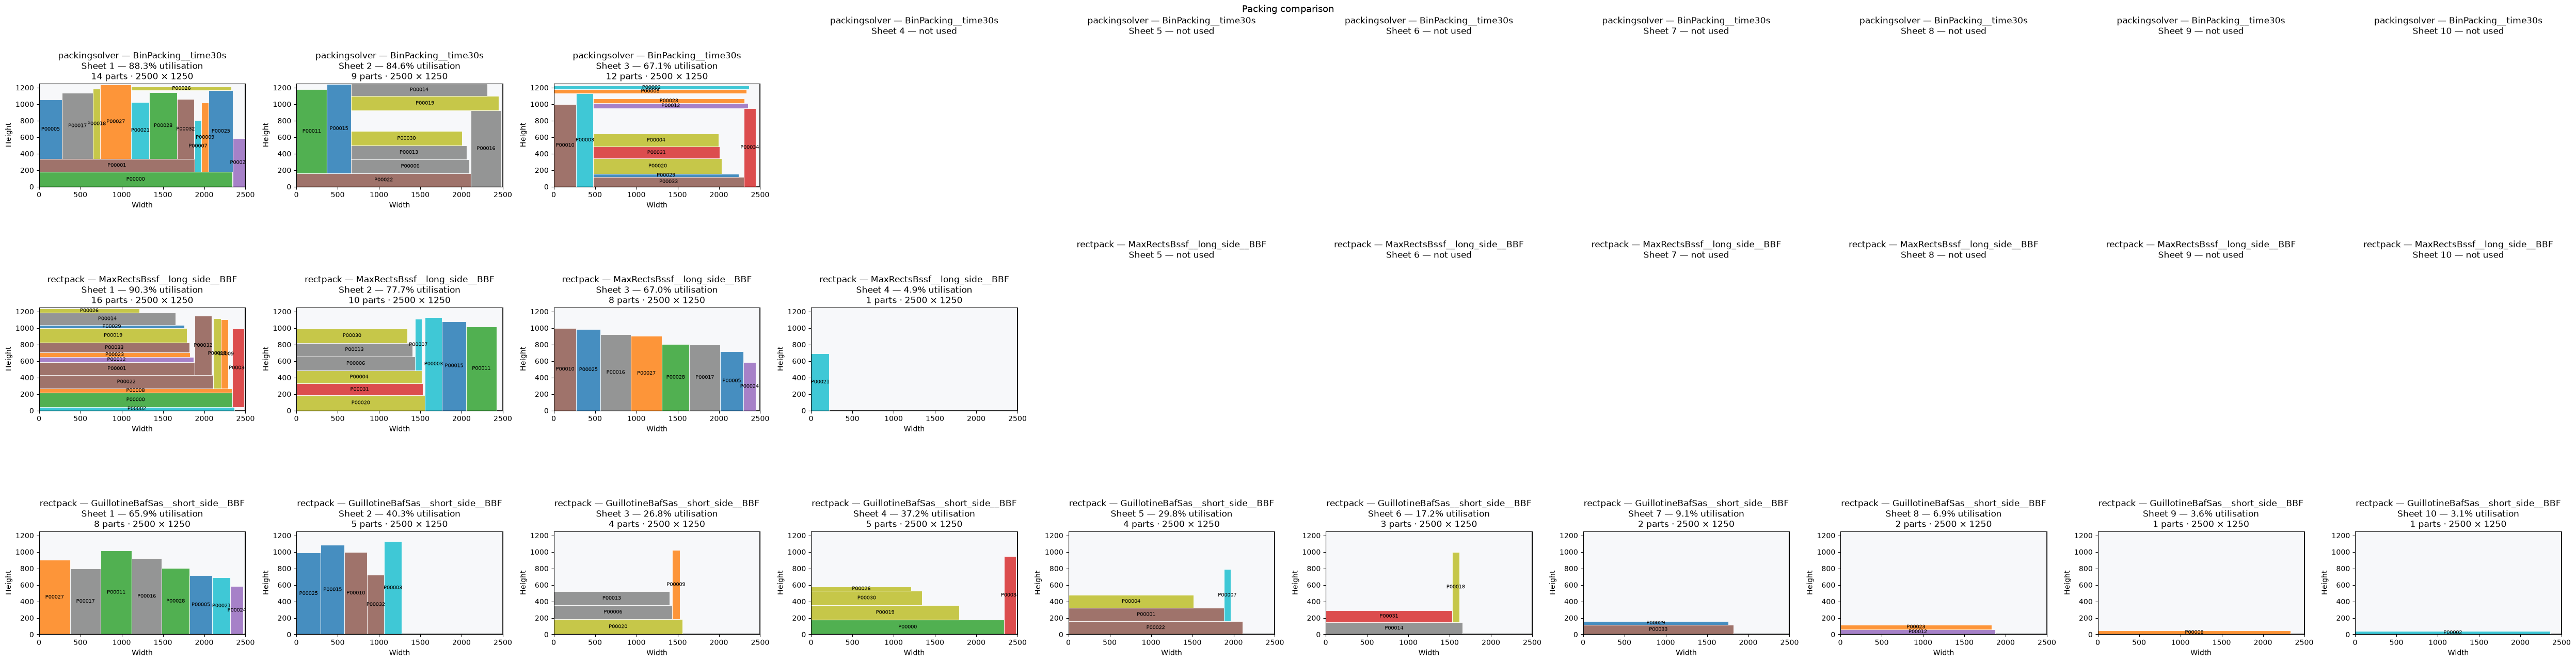

In [13]:
from cutting_benchmark.rectangle_visualization import compare_rectangle_results

compare_rectangle_results([ps_results,
    best_rp_results,
    worst_rp_results
    ]
)

(<Figure size 2000x1350 with 12 Axes>,
 array([[<Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 1 — 88.3% utilisation\n14 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 2 — 84.6% utilisation\n9 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 3 — 67.1% utilisation\n12 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'packingsolver — BinPacking__time30s\nSheet 4 — not used'}>],
        [<Axes: title={'center': 'rectpack — MaxRectsBssf__long_side__BBF\nSheet 1 — 90.3% utilisation\n16 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'rectpack — MaxRectsBssf__long_side__BBF\nSheet 2 — 77.7% utilisation\n10 parts · 2500 × 1250'}, xlabel='Width', ylabel='Height'>,
         <Axes: title={'center': 'rectpack — MaxRectsBssf__

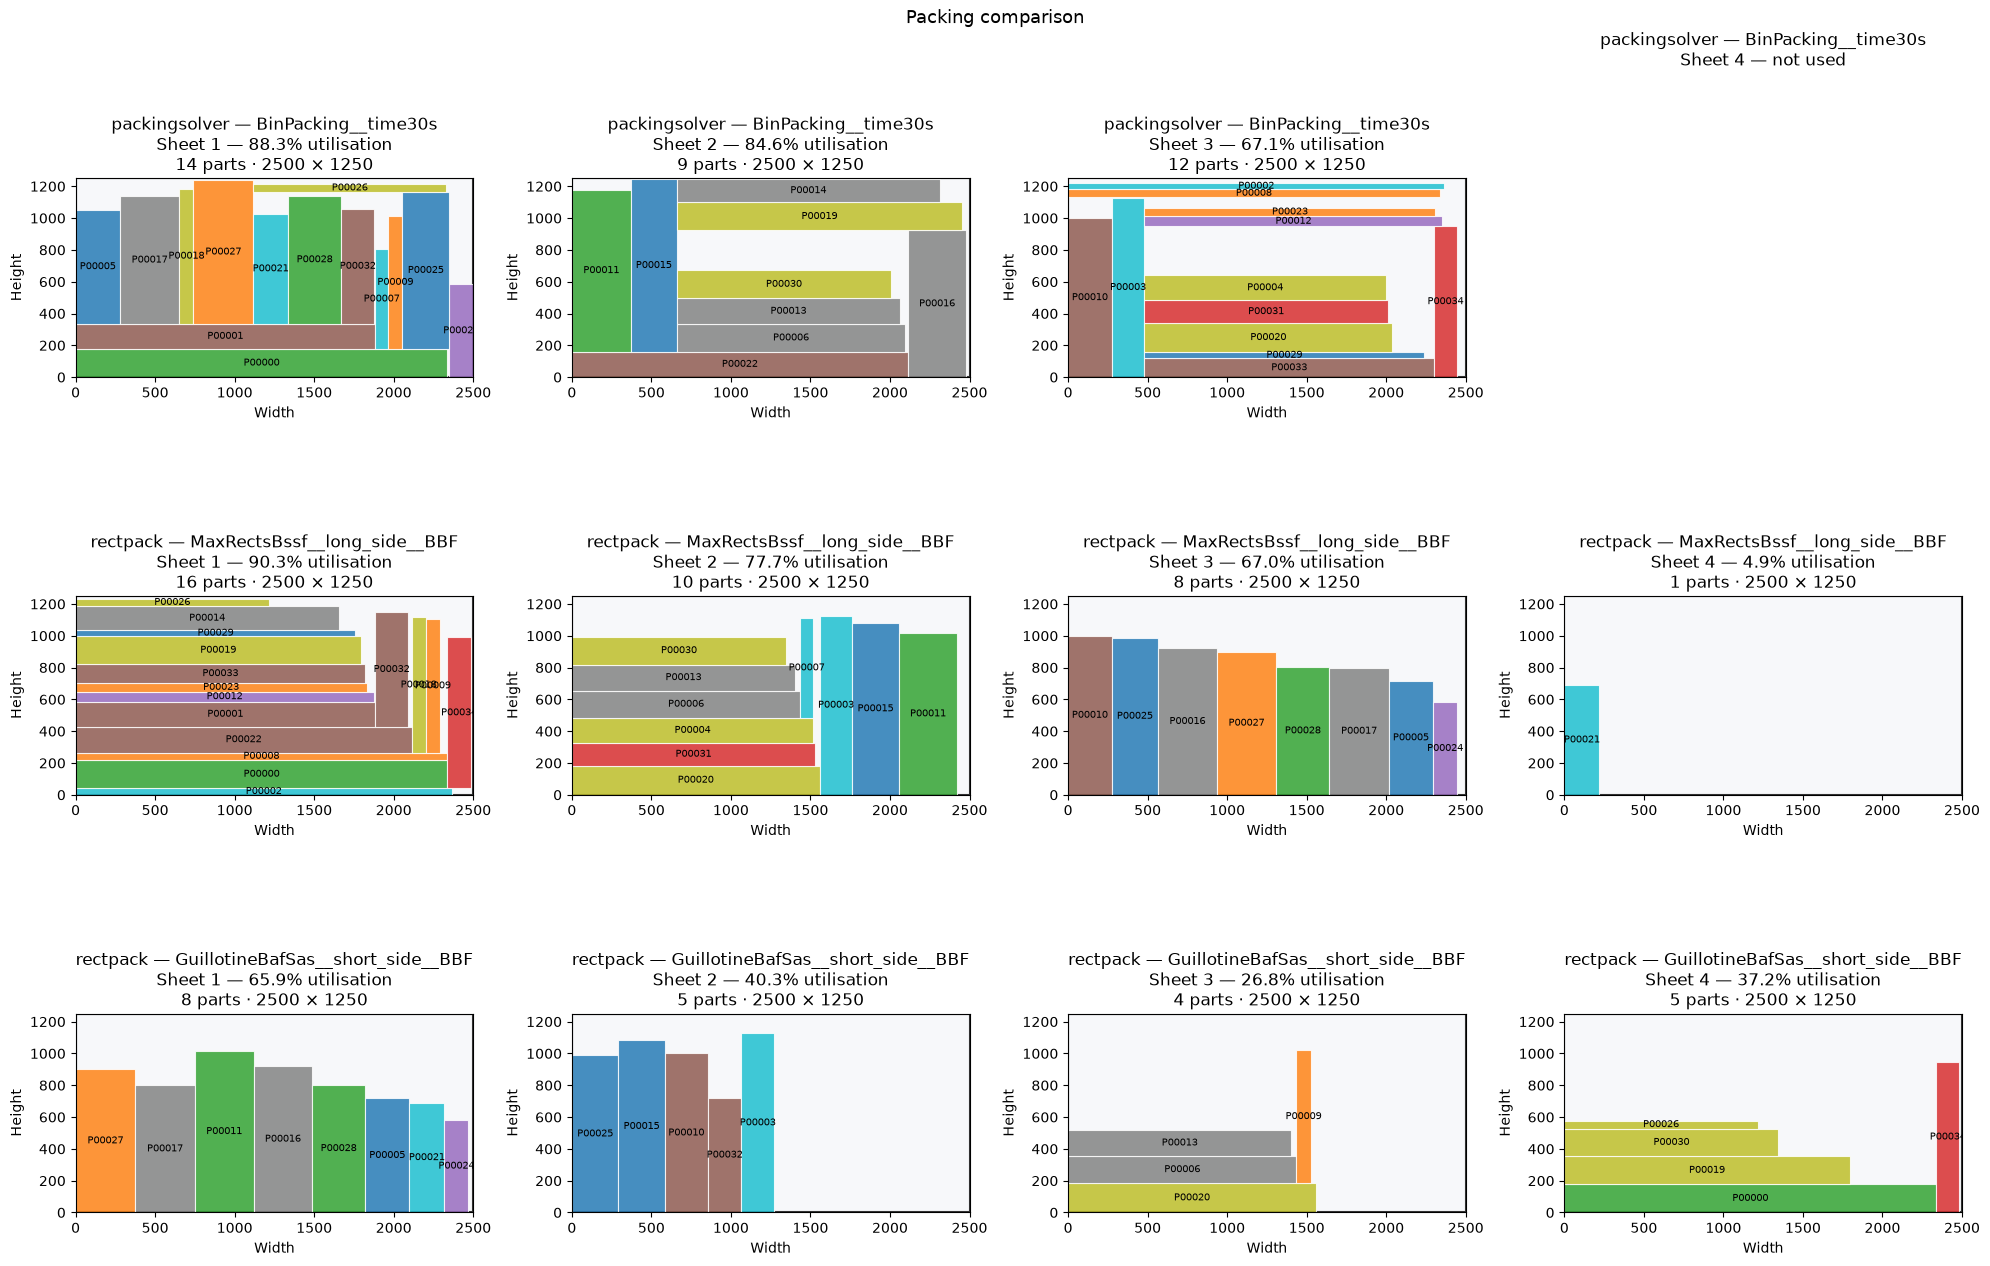

In [14]:
compare_rectangle_results([ps_results,
    best_rp_results,
    worst_rp_results
    ], sheets=range(4)
)

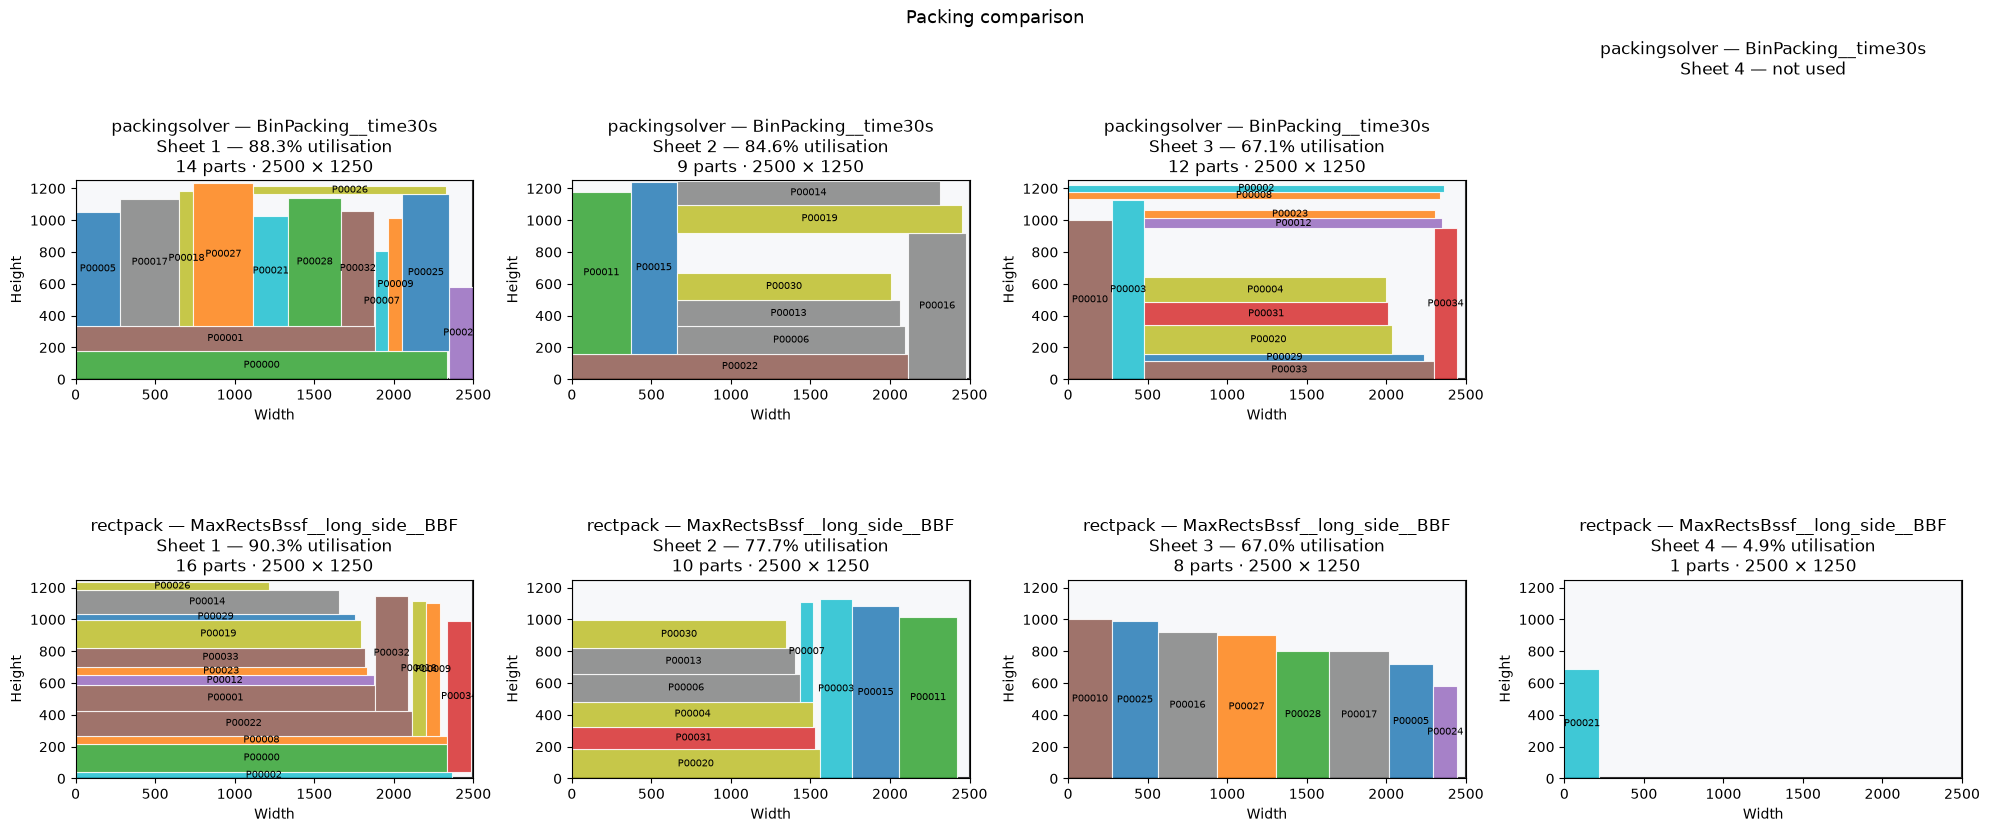

In [17]:
fig, axes =compare_rectangle_results([ps_results,
    best_rp_results
    ]
)

output_path = Path(PROJECT_ROOT / "docs/figures/packing_comparison.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")